In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style= "darkgrid", color_codes = True)
from tensorflow.keras.applications import MobileNetV3Small 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Dense, Flatten, Dropout, Input, GlobalAveragePooling2D
from keras.regularizers import l2
import warnings
warnings.filterwarnings('ignore')
tf.config.optimizer.set_jit(False)
# Vérifier si GPU est disponible
if tf.config.list_physical_devices('GPU'):
    # Permettre la croissance de la mémoire GPU
    for gpu in tf.config.experimental.list_physical_devices('GPU'):
        tf.config.experimental.set_memory_growth(gpu, True)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

2025-04-14 10:05:41.238891: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-14 10:05:41.251975: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744617941.266378   43987 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744617941.269784   43987 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1744617941.283958   43987 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Define image size and other parameters
img_width, img_height = 128, 128
batchsize = 32
epochs = 6
num_of_class = 2
import tensorflow as tf
import os
import random

def create_balanced_three_class_dataset(directory, batch_size, img_size):
    normal_path = os.path.join(directory, 'NORMAL')
    pneumonia_path = os.path.join(directory, 'PNEUMONIA')

    # Récupération des fichiers et attribution des labels one-hot
    normal_files = [(os.path.join(normal_path, f), [1,0,0]) 
                    for f in os.listdir(normal_path) 
                    if f.endswith(('.jpeg', '.jpg', '.png'))]

    viral_files = [(os.path.join(pneumonia_path, f), [0,1,0]) 
                   for f in os.listdir(pneumonia_path) 
                   if 'virus' in f.lower() and f.endswith(('.jpeg', '.jpg', '.png'))]

    bacterial_files = [(os.path.join(pneumonia_path, f), [0,0,1]) 
                       for f in os.listdir(pneumonia_path) 
                       if 'bacteria' in f.lower() and f.endswith(('.jpeg', '.jpg', '.png'))]

    # Calcul du plus petit nombre d'images disponibles
    min_count = min(len(normal_files), len(viral_files), len(bacterial_files))

    # Équilibrer les classes
    random.shuffle(normal_files)
    random.shuffle(viral_files)
    random.shuffle(bacterial_files)

    normal_files = normal_files[:min_count]
    viral_files = viral_files[:min_count]
    bacterial_files = bacterial_files[:min_count]

    # Fusionner toutes les données
    all_data = normal_files + viral_files + bacterial_files
    random.shuffle(all_data)

    print(f"[{directory}] Normal: {len(normal_files)}, Viral: {len(viral_files)}, Bacterial: {len(bacterial_files)}")


    file_paths, labels = zip(*all_data)

    # Création du dataset
    def load_and_preprocess_image(file_path, label):
        img = tf.io.read_file(file_path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, img_size)
        img = img / 255.0
        return img, label

    dataset = tf.data.Dataset.from_tensor_slices((list(file_paths), list(labels)))
    dataset = dataset.map(load_and_preprocess_image)
    dataset = dataset.shuffle(buffer_size=len(all_data))
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return dataset


# Charger les datasets
img_size = (img_width, img_height)
train = create_balanced_three_class_dataset('chest_xray/train', batchsize, img_size)
validation = create_balanced_three_class_dataset('chest_xray/val', batchsize, img_size)
test = create_balanced_three_class_dataset('chest_xray/test', batchsize, img_size)

# Vérifier la forme des données
for images, labels in train.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Sample labels:", labels[0])  # Devrait montrer un vecteur one-hot de taille 3

[chest_xray/train] Normal: 1341, Viral: 1341, Bacterial: 1341
[chest_xray/val] Normal: 8, Viral: 8, Bacterial: 8
[chest_xray/test] Normal: 148, Viral: 148, Bacterial: 148


I0000 00:00:1744617943.824769   43987 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3539 MB memory:  -> device: 0, name: NVIDIA RTX 1000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Images shape: (32, 128, 128, 3)
Labels shape: (32, 3)
Sample labels: tf.Tensor([0 1 0], shape=(3,), dtype=int32)


2025-04-14 10:05:46.953709: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Format des labels: [1 0 0]
Label 0: [1.0, 0.0, 0.0]
Label 1: [1.0, 0.0, 0.0]
Label 2: [0.0, 1.0, 0.0]
Label 3: [1.0, 0.0, 0.0]


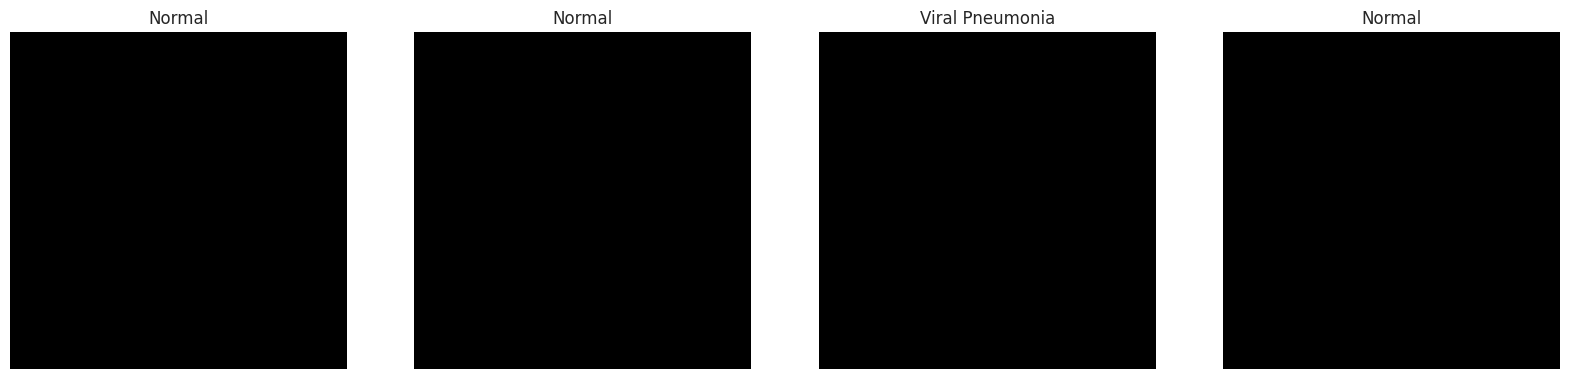

In [3]:
data_iterator = train.as_numpy_iterator()
batch = data_iterator.next()

# Afficher un exemple de label pour debug
print("Format des labels:", batch[1][0])

# Créer un dictionnaire pour convertir les labels one-hot en texte
label_dict = {
    '[1.0, 0.0, 0.0]': "Normal",
    '[0.0, 1.0, 0.0]': "Viral Pneumonia",
    '[0.0, 0.0, 1.0]': "Bacterial Pneumonia"
}

fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    # Convertir le label en string avec le bon format
    label_str = str([float(x) for x in batch[1][idx].tolist()])
    print(f"Label {idx}:", label_str)  # Debug
    label = label_dict.get(label_str, "Unknown")
    ax[idx].title.set_text(label)
    ax[idx].axis('off')

plt.show()

In [4]:
from tensorflow.keras.utils import to_categorical
# Définir une taille fixe pour toutes les images
IMG_SIZE = (128, 128)  # Taille standard pour VGG16

# Extracting Features and Labels
x_train = []
y_train = []
x_val = []
y_val = []
x_test = []
y_test = []

# Fonction pour traiter un batch
def process_batch(batch):
    features, labels = batch
    features = tf.image.resize(features, IMG_SIZE)
    return features.numpy(), labels.numpy()

# Traiter les données d'entraînement
for batch in train:
    features, labels = process_batch(batch)
    x_train.extend(features)
    y_train.extend(labels)

# Traiter les données de test
for batch in test:
    features, labels = process_batch(batch)
    x_test.extend(features)
    y_test.extend(labels)

# Traiter les données de validation
for batch in validation:
    features, labels = process_batch(batch)
    x_val.extend(features)
    y_val.extend(labels)

# Convertir en arrays numpy
x_train = np.array(x_train, dtype=np.float32)
x_val = np.array(x_val, dtype=np.float32)
x_test = np.array(x_test, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

# Normaliser les images
x_train = tf.image.resize(x_train, IMG_SIZE)
x_val = tf.image.resize(x_val, IMG_SIZE)
x_test = tf.image.resize(x_test, IMG_SIZE)


# Vérifier les shapes
print("Shape de x_train:", x_train.shape)
print("Shape de y_train:", y_train.shape)
print("Shape de x_val:", x_val.shape)
print("Shape de y_val:", y_val.shape)
print("Shape de x_test:", x_test.shape)
print("Shape de y_test:", y_test.shape)

# Vérifier les valeurs uniques dans les labels
print("\nValeurs uniques dans y_train:", np.unique(y_train, axis=0))

2025-04-14 10:05:54.130287: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-04-14 10:05:54.553957: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Shape de x_train: (4023, 128, 128, 3)
Shape de y_train: (4023, 3)
Shape de x_val: (24, 128, 128, 3)
Shape de y_val: (24, 3)
Shape de x_test: (444, 128, 128, 3)
Shape de y_test: (444, 3)

Valeurs uniques dans y_train: [[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]


In [5]:
# check the shapes of 'x_train' and 'y_train':
print("Shape of 'x_train':", x_train.shape)
print("Shape of 'y_train':", y_train.shape)
print("Shape of 'x_val':", x_val.shape)
print("Shape of 'y_val':", y_val.shape)
print("Shape of 'x_test':", x_test.shape)
print("Shape of 'y_test':", y_test.shape)

Shape of 'x_train': (4023, 128, 128, 3)
Shape of 'y_train': (4023, 3)
Shape of 'x_val': (24, 128, 128, 3)
Shape of 'y_val': (24, 3)
Shape of 'x_test': (444, 128, 128, 3)
Shape of 'y_test': (444, 3)


In [6]:
def create_model():
    base_model = MobileNetV3Small(weights='imagenet', 
                      include_top=False, 
                      input_shape=(128, 128, 3))

    base_model.trainable = False
    
    model = Sequential([
        base_model,
        Flatten(),
        Dropout(0.4),
        Dense(256, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.3),
        Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        Dense(3, activation='softmax')
    ])
    
    # Learning rate plus faible pour un meilleur apprentissage
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)
    
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy', 'Precision', 'Recall']
    )

    model.summary()
    
    return model

Fold 1/5
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 4, 4, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,331,955 (12.71 MB)

 Trainable params: 2,392,835 (9.13 MB)

...

  8/101 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - Precision: 0.3304 - Recall: 0.1841 - accuracy: 0.3433 - loss: 7.9820

I0000 00:00:1744617971.678590   44115 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


100/101 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - Precision: 0.3661 - Recall: 0.1095 - accuracy: 0.3364 - loss: 7.0483

2025-04-14 10:06:14.489124: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5946', 4 bytes spill stores, 4 bytes spill loads



101/101 ━━━━━━━━━━━━━━━━━━━━ 32s 201ms/step - Precision: 0.3662 - Recall: 0.1090 - accuracy: 0.3365 - loss: 7.0337 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3478 - val_loss: 5.0726 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - Precision: 0.4477 - Recall: 0.0477 - accuracy: 0.3774 - loss: 4.7268 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3478 - val_loss: 3.9257 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - Precision: 0.4066 - Recall: 0.0327 - accuracy: 0.3640 - loss: 3.7694 - val_Precision: 0.6638 - val_Recall: 0.2870 - val_accuracy: 0.3354 - val_loss: 3.3770 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - Precision: 0.4839 - Recall: 0.0605 - accuracy: 0.3812 - loss: 3.2624 - val_Precision: 1.0000 - val_Recall: 0.0012 - val_accuracy: 0.4696 - val_loss: 2.9406 - learning_rate: 1.0000e-04
Epoch 5/20
101/101 ━━━━━━━━━━━━━━━━━━

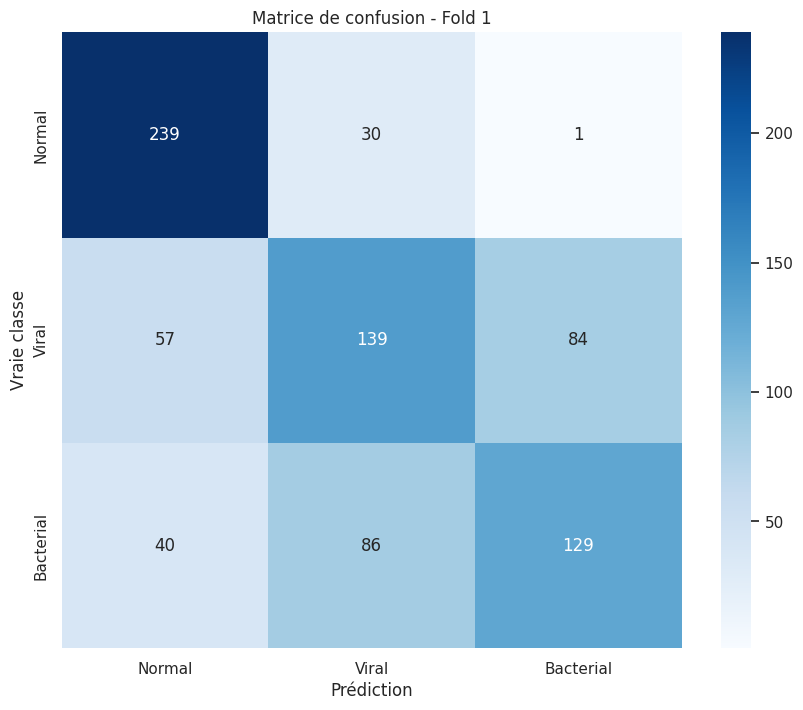


Métriques détaillées pour le Fold 1:

Classe: Normal
True Positives (TP): 239
True Negatives (TN): 438
False Positives (FP): 97
False Negatives (FN): 31
Precision: 0.7113
Recall: 0.8852

Classe: Viral
True Positives (TP): 139
True Negatives (TN): 409
False Positives (FP): 116
False Negatives (FN): 141
Precision: 0.5451
Recall: 0.4964

Classe: Bacterial
True Positives (TP): 129
True Negatives (TN): 465
False Positives (FP): 85
False Negatives (FN): 126
Precision: 0.6028
Recall: 0.5059

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.71      0.89      0.79       270
       Viral       0.55      0.50      0.52       280
   Bacterial       0.60      0.51      0.55       255

    accuracy                           0.63       805
   macro avg       0.62      0.63      0.62       805
weighted avg       0.62      0.63      0.62       805



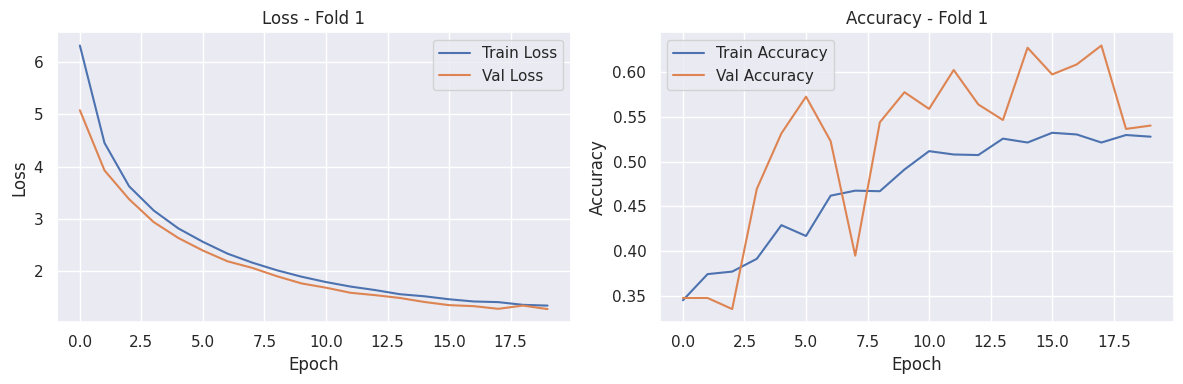

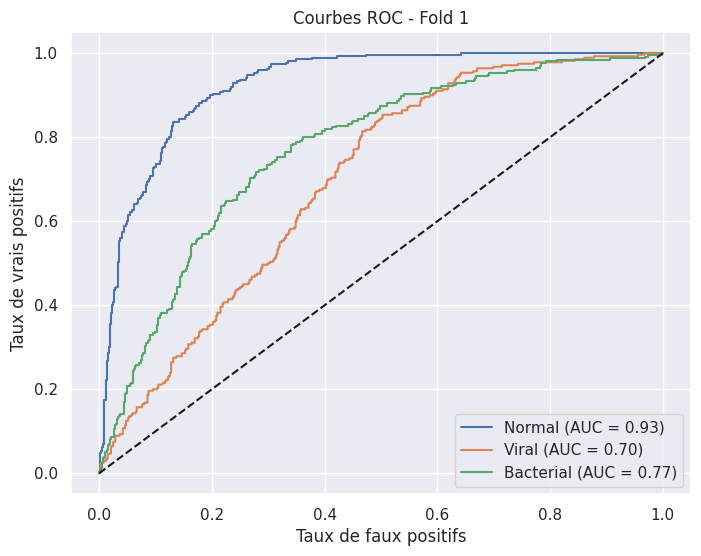

Fold 2/5


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 4, 4, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,331,955 (12.71 MB)

 Trainable params: 2,392,835 (9.13 MB)

 Non-trainable params: 939,120 (3.58 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 17s 100ms/step - Precision: 0.3878 - Recall: 0.1375 - accuracy: 0.3577 - loss: 7.0022 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3230 - val_loss: 5.0753 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - Precision: 0.4157 - Recall: 0.0551 - accuracy: 0.3541 - loss: 4.7271 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3429 - val_loss: 3.8852 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - Precision: 0.4341 - Recall: 0.0416 - accuracy: 0.3721 - loss: 3.7330 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.4907 - val_loss: 3.2782 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - Precision: 0.4839 - Recall: 0.0630 - accuracy: 0.3970 - loss: 3.1979 - val_Precision: 0.8923 - val_Recall: 0.0720 - val_accuracy: 0.3863 - val_loss: 2.9056 - learning_rate: 1.0000e-04
Epoch 5/20
101/101

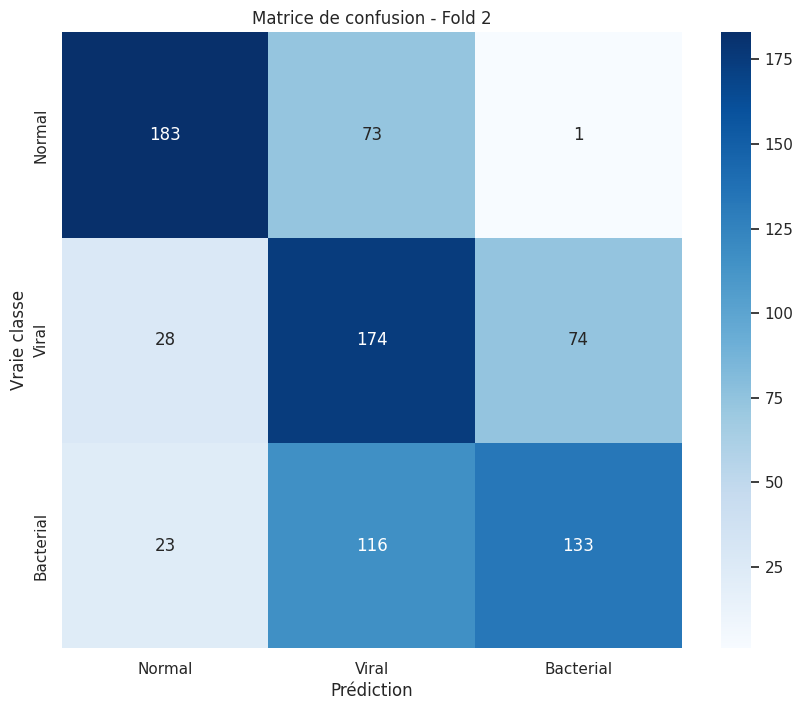


Métriques détaillées pour le Fold 2:

Classe: Normal
True Positives (TP): 183
True Negatives (TN): 497
False Positives (FP): 51
False Negatives (FN): 74
Precision: 0.7821
Recall: 0.7121

Classe: Viral
True Positives (TP): 174
True Negatives (TN): 340
False Positives (FP): 189
False Negatives (FN): 102
Precision: 0.4793
Recall: 0.6304

Classe: Bacterial
True Positives (TP): 133
True Negatives (TN): 458
False Positives (FP): 75
False Negatives (FN): 139
Precision: 0.6394
Recall: 0.4890

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.78      0.71      0.75       257
       Viral       0.48      0.63      0.54       276
   Bacterial       0.64      0.49      0.55       272

    accuracy                           0.61       805
   macro avg       0.63      0.61      0.61       805
weighted avg       0.63      0.61      0.61       805



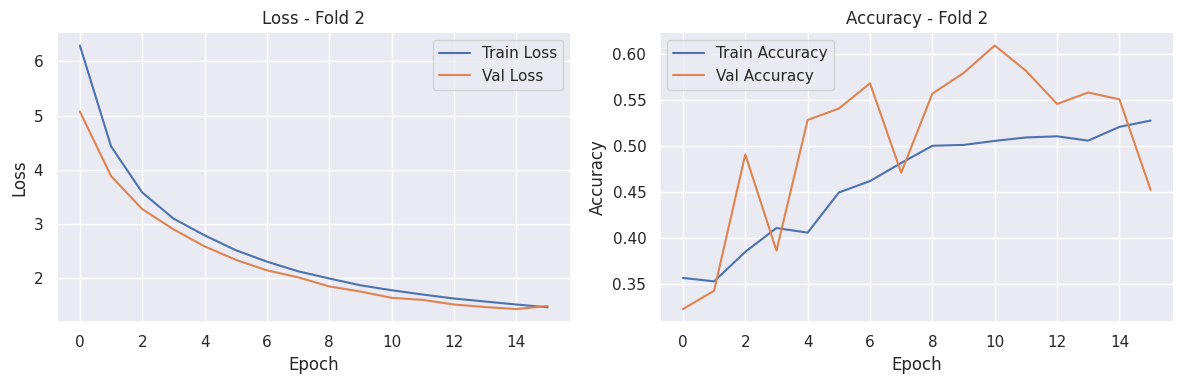

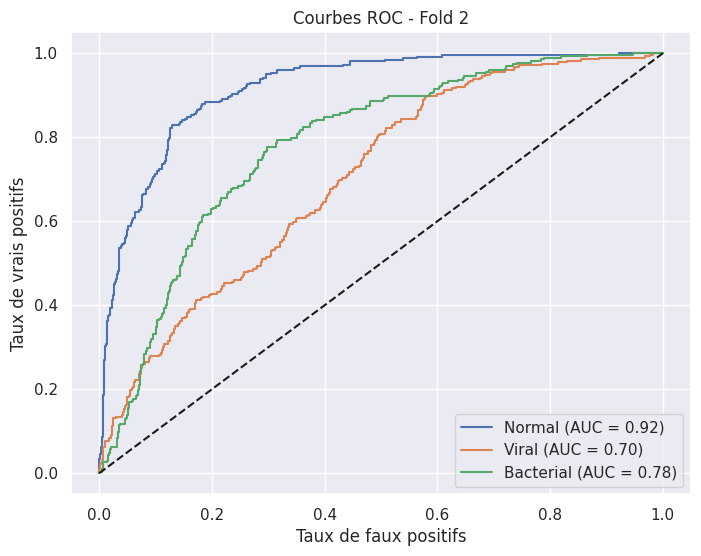

Fold 3/5


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 4, 4, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,331,955 (12.71 MB)

 Trainable params: 2,392,835 (9.13 MB)

 Non-trainable params: 939,120 (3.58 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 16s 97ms/step - Precision: 0.3307 - Recall: 0.1128 - accuracy: 0.3348 - loss: 7.0378 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3578 - val_loss: 5.0333 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - Precision: 0.3968 - Recall: 0.0269 - accuracy: 0.3616 - loss: 4.6948 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.4099 - val_loss: 3.8592 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - Precision: 0.4166 - Recall: 0.0312 - accuracy: 0.3647 - loss: 3.7128 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.5491 - val_loss: 3.2607 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - Precision: 0.4323 - Recall: 0.0496 - accuracy: 0.3863 - loss: 3.1833 - val_Precision: 1.0000 - val_Recall: 0.0037 - val_accuracy: 0.4472 - val_loss: 2.8675 - learning_rate: 1.0000e-04
Epoch 5/20
101/101 

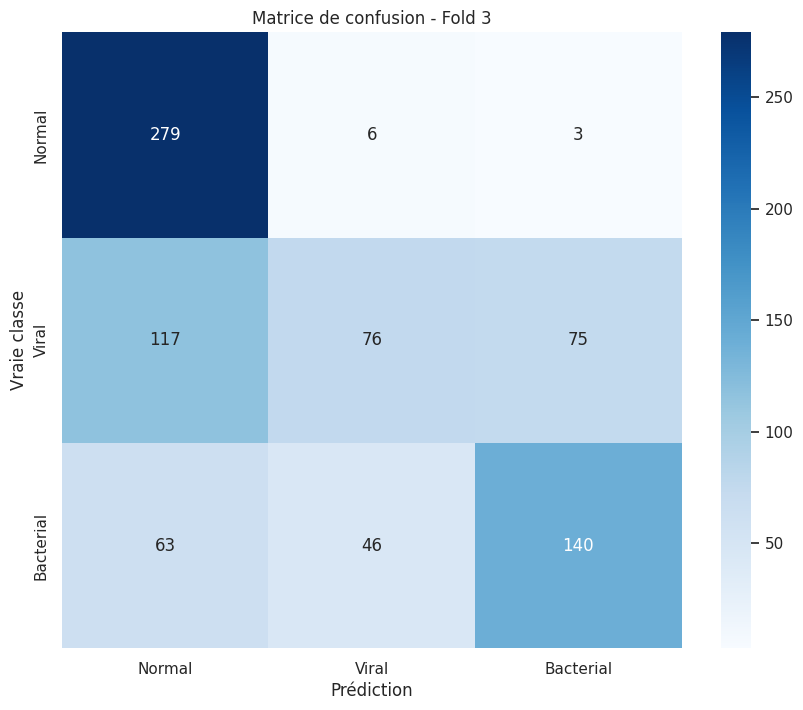


Métriques détaillées pour le Fold 3:

Classe: Normal
True Positives (TP): 279
True Negatives (TN): 337
False Positives (FP): 180
False Negatives (FN): 9
Precision: 0.6078
Recall: 0.9688

Classe: Viral
True Positives (TP): 76
True Negatives (TN): 485
False Positives (FP): 52
False Negatives (FN): 192
Precision: 0.5938
Recall: 0.2836

Classe: Bacterial
True Positives (TP): 140
True Negatives (TN): 478
False Positives (FP): 78
False Negatives (FN): 109
Precision: 0.6422
Recall: 0.5622

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.61      0.97      0.75       288
       Viral       0.59      0.28      0.38       268
   Bacterial       0.64      0.56      0.60       249

    accuracy                           0.61       805
   macro avg       0.61      0.60      0.58       805
weighted avg       0.61      0.61      0.58       805



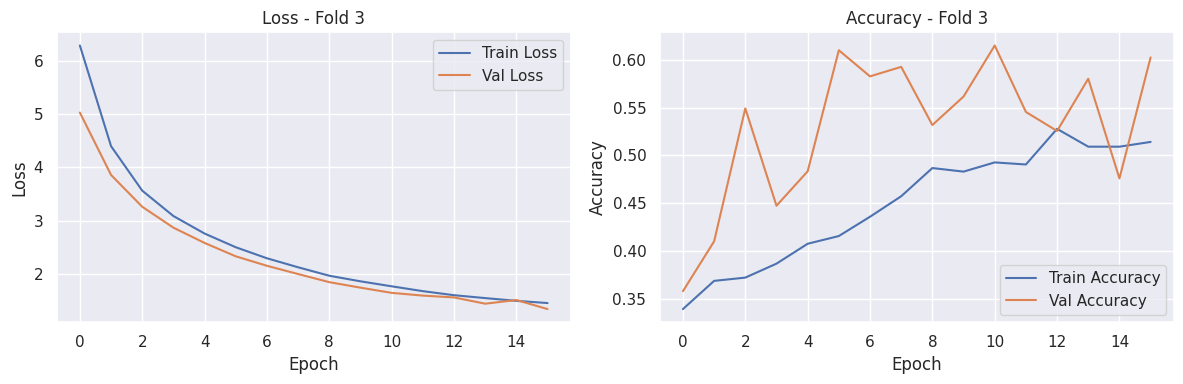

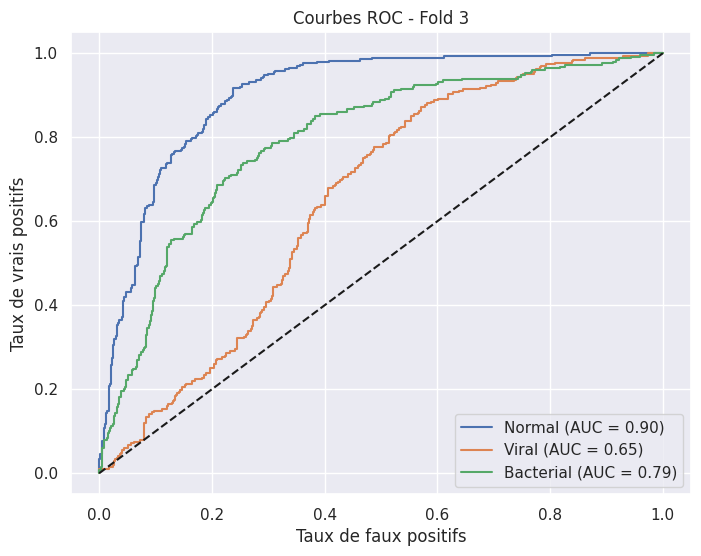

Fold 4/5


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 4, 4, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,331,955 (12.71 MB)

 Trainable params: 2,392,835 (9.13 MB)

 Non-trainable params: 939,120 (3.58 MB)

Epoch 1/20
 99/101 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - Precision: 0.3082 - Recall: 0.0821 - accuracy: 0.3131 - loss: 7.0517

2025-04-14 10:08:43.270186: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5946', 4 bytes spill stores, 4 bytes spill loads



101/101 ━━━━━━━━━━━━━━━━━━━━ 26s 185ms/step - Precision: 0.3093 - Recall: 0.0816 - accuracy: 0.3138 - loss: 7.0294 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3060 - val_loss: 5.0759 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - Precision: 0.3863 - Recall: 0.0629 - accuracy: 0.3558 - loss: 4.7279 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.5211 - val_loss: 3.8750 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - Precision: 0.4228 - Recall: 0.0520 - accuracy: 0.3865 - loss: 3.7392 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3122 - val_loss: 3.3034 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - Precision: 0.5828 - Recall: 0.0725 - accuracy: 0.4023 - loss: 3.2138 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.4527 - val_loss: 2.8966 - learning_rate: 1.0000e-04
Epoch 5/20
101/101 ━━

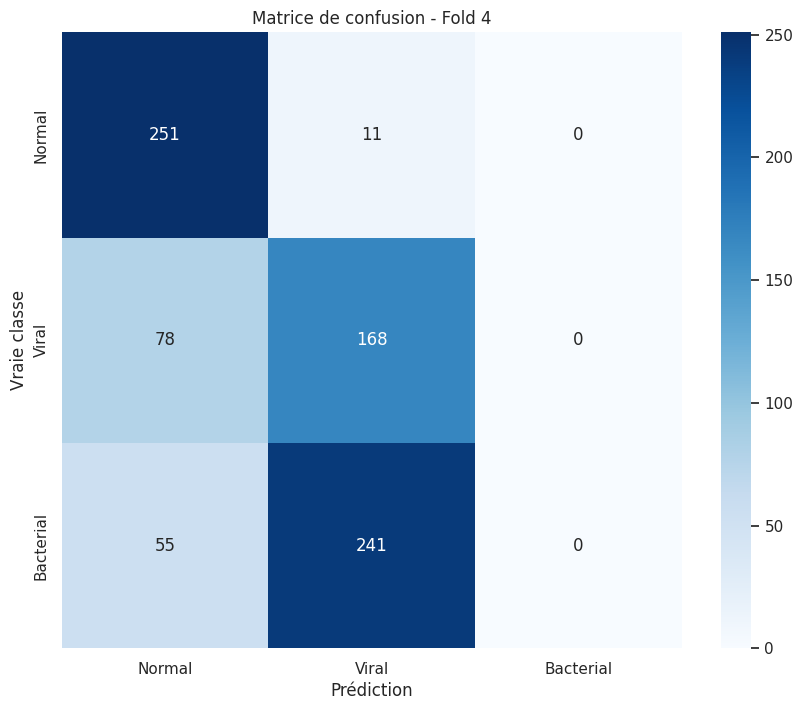


Métriques détaillées pour le Fold 4:

Classe: Normal
True Positives (TP): 251
True Negatives (TN): 409
False Positives (FP): 133
False Negatives (FN): 11
Precision: 0.6536
Recall: 0.9580

Classe: Viral
True Positives (TP): 168
True Negatives (TN): 306
False Positives (FP): 252
False Negatives (FN): 78
Precision: 0.4000
Recall: 0.6829

Classe: Bacterial
True Positives (TP): 0
True Negatives (TN): 508
False Positives (FP): 0
False Negatives (FN): 296
Precision: 0.0000
Recall: 0.0000

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.65      0.96      0.78       262
       Viral       0.40      0.68      0.50       246
   Bacterial       0.00      0.00      0.00       296

    accuracy                           0.52       804
   macro avg       0.35      0.55      0.43       804
weighted avg       0.34      0.52      0.41       804



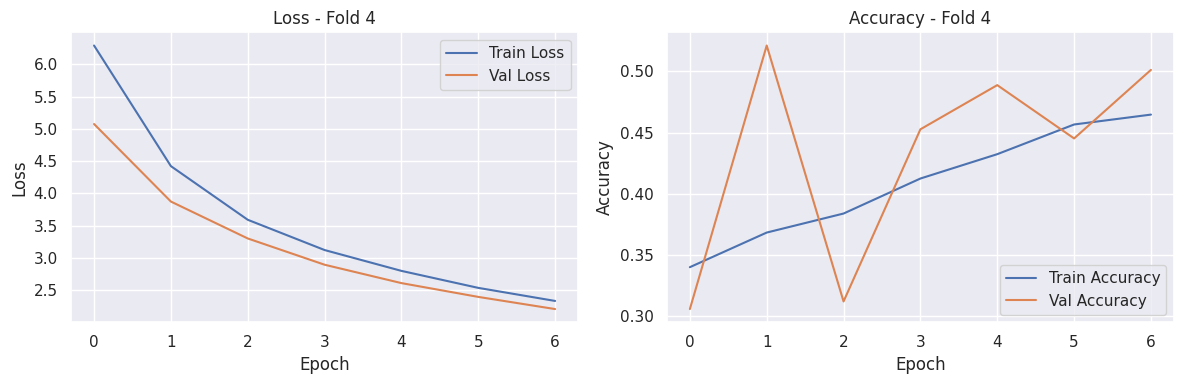

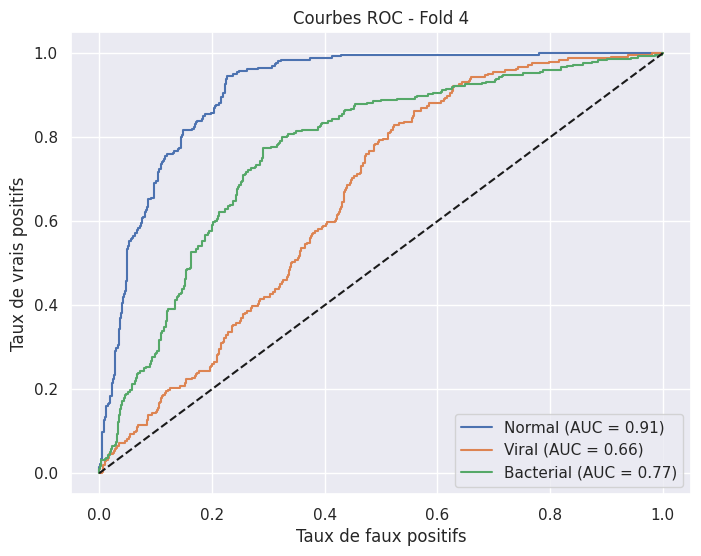

Fold 5/5


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 4, 4, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,331,955 (12.71 MB)

 Trainable params: 2,392,835 (9.13 MB)

 Non-trainable params: 939,120 (3.58 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - Precision: 0.3163 - Recall: 0.0988 - accuracy: 0.3365 - loss: 7.0250 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3346 - val_loss: 5.0741 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - Precision: 0.3357 - Recall: 0.0326 - accuracy: 0.3546 - loss: 4.7522 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.4789 - val_loss: 3.9150 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - Precision: 0.3692 - Recall: 0.0292 - accuracy: 0.3569 - loss: 3.7882 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.3284 - val_loss: 3.3516 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - Precision: 0.4765 - Recall: 0.0273 - accuracy: 0.3712 - loss: 3.2653 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.5062 - val_loss: 2.9659 - learning_rate: 1.0000e-04
Epoch 5/20

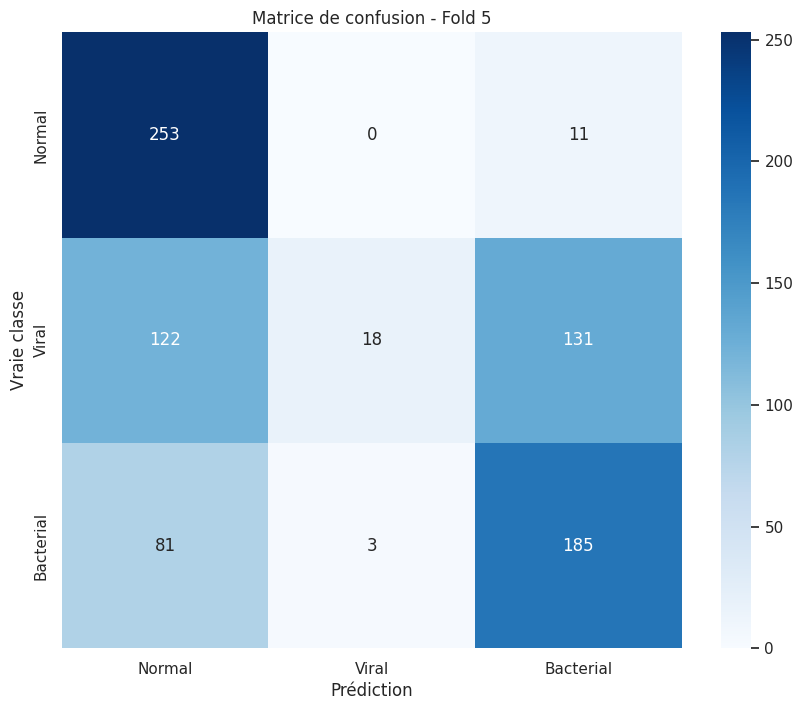


Métriques détaillées pour le Fold 5:

Classe: Normal
True Positives (TP): 253
True Negatives (TN): 337
False Positives (FP): 203
False Negatives (FN): 11
Precision: 0.5548
Recall: 0.9583

Classe: Viral
True Positives (TP): 18
True Negatives (TN): 530
False Positives (FP): 3
False Negatives (FN): 253
Precision: 0.8571
Recall: 0.0664

Classe: Bacterial
True Positives (TP): 185
True Negatives (TN): 393
False Positives (FP): 142
False Negatives (FN): 84
Precision: 0.5657
Recall: 0.6877

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.55      0.96      0.70       264
       Viral       0.86      0.07      0.12       271
   Bacterial       0.57      0.69      0.62       269

    accuracy                           0.57       804
   macro avg       0.66      0.57      0.48       804
weighted avg       0.66      0.57      0.48       804



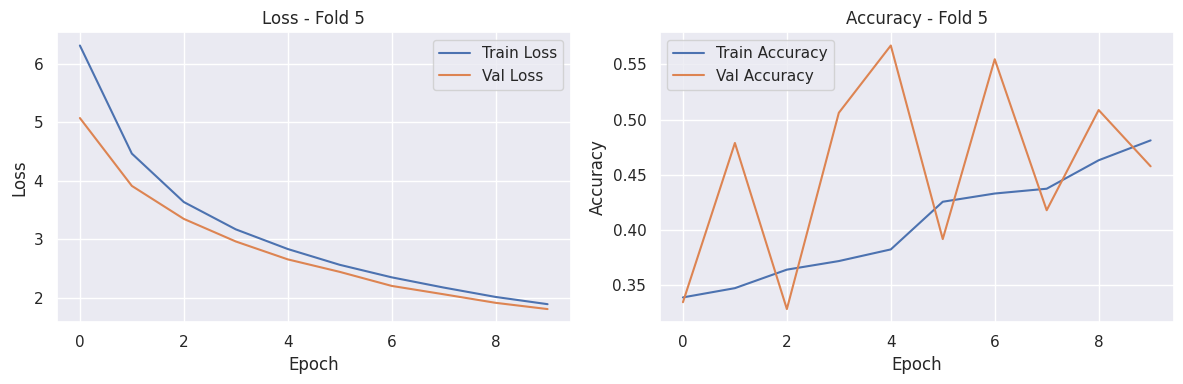

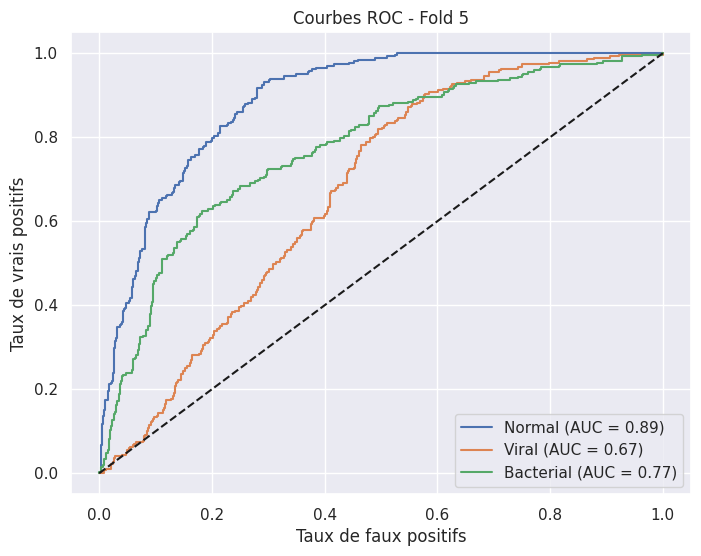


Résultats finaux:
Score moyen: 0.5883 (+/- 0.0395)


In [7]:
from sklearn.model_selection import KFold
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Convertir les données en numpy arrays si ce n'est pas déjà fait
x_train_np = x_train.numpy() if isinstance(x_train, tf.Tensor) else x_train
y_train_np = y_train.numpy() if isinstance(y_train, tf.Tensor) else y_train

# Définir le nombre de folds
n_folds = 5
batch_size = 32
epochs = 20
kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
class_names = ['Normal', 'Viral', 'Bacterial']
# Boucle de validation croisée
val_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(x_train_np)):
    print(f'Fold {fold + 1}/{n_folds}')
    
    model = create_model()
    
    # Utiliser les arrays numpy pour l'indexation
    x_train_fold = x_train_np[train_idx]
    y_train_fold = y_train_np[train_idx]
    x_val_fold = x_train_np[val_idx]
    y_val_fold = y_train_np[val_idx]
    
    # Convertir en tensors pour l'entraînement si nécessaire
    x_train_fold = tf.convert_to_tensor(x_train_fold)
    y_train_fold = tf.convert_to_tensor(y_train_fold)
    x_val_fold = tf.convert_to_tensor(x_val_fold)
    y_val_fold = tf.convert_to_tensor(y_val_fold)
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True
    )
    
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=0.00001
    )

    history = model.fit(
        x_train_fold,
        y_train_fold,
        validation_data=(x_val_fold, y_val_fold),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1,
        callbacks=[early_stopping, reduce_lr]
    )
    
    val_score = model.evaluate(x_val_fold, y_val_fold, verbose=0)
    val_scores.append(val_score[1])
    
    print(f"Fold {fold + 1} - Accuracy: {val_score[1]:.4f}")
    
     # Matrice de confusion avec plus de détails
    y_pred = model.predict(x_val_fold)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_val_fold, axis=1)
    
    
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    
    # Calculer TP, TN, FP, FN pour chaque classe
    n_classes = 3
    metrics = {}
    
    for i in range(n_classes):
        TP = cm[i, i]
        FP = np.sum(cm[:, i]) - TP
        FN = np.sum(cm[i, :]) - TP
        TN = np.sum(cm) - TP - FP - FN
        
        metrics[class_names[i]] = {
            'TP': TP,
            'TN': TN,
            'FP': FP,
            'FN': FN,
            'Precision': TP / (TP + FP) if (TP + FP) > 0 else 0,
            'Recall': TP / (TP + FN) if (TP + FN) > 0 else 0
        }
    
    # Afficher la matrice de confusion
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f'Matrice de confusion - Fold {fold + 1}')
    plt.ylabel('Vraie classe')
    plt.xlabel('Prédiction')
    plt.show()
    
    # Afficher les métriques détaillées
    print(f"\nMétriques détaillées pour le Fold {fold + 1}:")
    for classe, m in metrics.items():
        print(f"\nClasse: {classe}")
        print(f"True Positives (TP): {m['TP']}")
        print(f"True Negatives (TN): {m['TN']}")
        print(f"False Positives (FP): {m['FP']}")
        print(f"False Negatives (FN): {m['FN']}")
        print(f"Precision: {m['Precision']:.4f}")
        print(f"Recall: {m['Recall']:.4f}")
    
    # Afficher le rapport de classification complet
    print("\nRapport de classification détaillé:")
    print(classification_report(y_true_classes, y_pred_classes, 
                              target_names=class_names))

    # --- Courbes d'entraînement/validation ---
    plt.figure(figsize=(12, 4))

    # Courbe de loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Courbe d'accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # --- Courbe ROC par classe ---
    # Assurer que les labels sont one-hot encodés
    from sklearn.preprocessing import label_binarize
    from sklearn.metrics import roc_curve, auc

    if y_val_fold.shape[1] != len(class_names):  # besoin d'encoder
        y_val_bin = label_binarize(np.argmax(y_val_fold, axis=1), classes=[0, 1, 2])
    else:
        y_val_bin = y_val_fold.numpy() if isinstance(y_val_fold, tf.Tensor) else y_val_fold

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(8, 6))
    for i in range(len(class_names)):
        plt.plot(fpr[i], tpr[i], label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title(f'Courbes ROC - Fold {fold + 1}')
    plt.xlabel('Taux de faux positifs')
    plt.ylabel('Taux de vrais positifs')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()
                              
   

print("\nRésultats finaux:")
print(f"Score moyen: {np.mean(val_scores):.4f} (+/- {np.std(val_scores):.4f})")

In [8]:
# Save the model
model.save('CNN_model.h5')